# 02 · EMT-TF Expression — Gao et al. 2021 (Breast Cancer, 10x)

The EMT-TF expression step is **unconditional** — always the final notebook, outside the gate chain
(§2). Gate 1 was **NO-GO**, so there is no trajectory/pseudotime; this notebook overlays the most
informative *detectable* EMT transcription factors on the (best-integration) breast malignant
manifold. The candidate panel is widened beyond Snail/Zeb/Twist to the **FOXC and PRRX** mesenchymal
families (03_eval fork 5); **VIM is excluded** — vimentin is a mesenchymal *marker*, not a TF
(04_test Chen). Overlay style follows the reference: a **categorical overlay of thresholded
expressers on a grey manifold**, not a continuous single-gene colormap (04_test Sun).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# read the processed malignant manifold (§6: expression reads processed.h5ad).
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells:', adata.shape[0], '| samples:', adata.obs['sample'].nunique())
adata

cells: 6411 | samples: 5


### Candidate panel → detection-gated selection
For each candidate TF: detection fraction and mean-in-expresser (no pseudotime ordering — Gate 1
NO-GO). Select the two most broadly-detected factors (frac > 0.03) so the overlay reflects real
signal, not a handful of dropout-driven cells.

In [4]:
panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present = [g for g in panel if g in adata.var_names]
missing = [g for g in panel if g not in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]
    rows.append((g, round((x > 0).mean(), 3), round(x[x > 0].mean() if (x > 0).any() else 0, 3), round(float(x.max()), 2)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_in_expr', 'max']).sort_values('frac_expr', ascending=False)
print('unmeasurable (absent after gene filter):', missing)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
sel = ok.head(2)['TF'].tolist()
print('\ndetectable EMT-TFs (frac>0.03):', ok.TF.tolist())
print('shown (two broadest):', sel)

unmeasurable (absent after gene filter): []
    TF  frac_expr  mean_in_expr  max
 FOXC1      0.285         0.858 2.94
 FOXC2      0.165         0.533 2.13
 SNAI2      0.156         0.714 3.83
TWIST1      0.153         0.516 2.05
 PRRX1      0.144         0.680 2.54
 PRRX2      0.112         0.681 2.39
 SNAI1      0.097         0.349 1.75
  ZEB2      0.028         0.641 2.40
  ZEB1      0.012         0.503 2.24
TWIST2      0.003         0.597 1.14

detectable EMT-TFs (frac>0.03): ['FOXC1', 'FOXC2', 'SNAI2', 'TWIST1', 'PRRX1', 'PRRX2', 'SNAI1']
shown (two broadest): ['FOXC1', 'FOXC2']


### Deliverable — `expression.pdf`
Categorical overlay of thresholded expressers on a grey manifold. Threshold = upper quartile among
expressers per factor, so a broadly-expressed TF is not washed across the whole manifold. House
`(3.5,1.5)` aspect, consistent UMAP orientation, external legend.

overlay thresholds (upper quartile among expressers): {'FOXC1': 1.12, 'FOXC2': 0.72} | cells shown: {'FOXC1': 457, 'FOXC2': 265}
FOXC1: 28.5% expressing; 457 shown (upper quartile)
FOXC2: 16.5% expressing; 265 shown (upper quartile)
saved expression.pdf


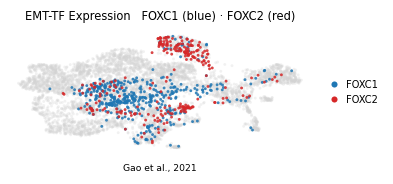

In [5]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
thr = {}
for g in sel:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
seln = {g: _vec(g) > thr[g] for g in sel}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g], 2) for g in thr},
      '| cells shown:', {g: int(seln[g].sum()) for g in seln})
order = sorted(sel, key=lambda g: -int(seln[g].sum()))
colors = {sel[0]: 'tab:blue', sel[1]: 'tab:red'}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=14, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[seln[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=14, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.legend(handles=[Line2D([0], [0], marker='o', color='w', markerfacecolor=colors[g],
                          markersize=5, label=g) for g in sel],
          loc='center left', bbox_to_anchor=(1.02, .5), frameon=False, fontsize=6.5, handletextpad=.2)
ax.set_title(f'EMT-TF Expression   {sel[0]} (blue) \u00b7 {sel[1]} (red)', size=7.5)
ax.text(.5, -.12, 'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
plt.show()
for g in sel:
    v = _vec(g)
    print(f'{g}: {(v>0).mean()*100:.1f}% expressing; {int(seln[g].sum())} shown (upper quartile)')
print('saved expression.pdf')